In [1]:
# imports
import torch
import torchvision
import pandas as pd
import matplotlib.pyplot as plt
import random
import re
from collections import Counter, defaultdict
from pathlib import Path
from ultralytics import YOLO

import cv2

%matplotlib inline

In [3]:
# helper code to convert the .csv files to a YOLO dataset

#  parameters
#.csv location for converted matlab data
dataFile = 'unfiltered_data/all_labels.csv'
# folder containing video files
videoFolderPath = 'unfiltered_data/Data/Video_V'
# outputFile name
outFile = 'yolo_dataset'

defSteps = 5

ranSeed = 42

def_n_check = 30

# data split between 70% train, 15% validation, 15% test
SPLIT = {"train": 0.70, "val": 0.15, "test": 0.15}
OUT = Path(outFile)
random.seed(ranSeed)

# load CSV
df = pd.read_csv(dataFile)
df["video"] = df["video"].fillna("")
df["class"] = df["class"].str.strip()

classes = sorted(df["class"].unique())
CLASS_MAP = {c: i for i, c in enumerate(classes)}
print("Classes found:", CLASS_MAP)

# index every video file by lowercase stem
video_index = {p.stem.lower(): p for p in Path(videoFolderPath).rglob("*")
               if p.suffix.lower() in {".mp4", ".avi", ".mov", ".mkv"}}
print(f"Found {len(video_index)} video files")

# Look up the video for a label file
def find_video(label_file, video_col):
    candidates = []
    if video_col:
        candidates.append(Path(video_col).stem)
    stem = Path(label_file).stem
    candidates += [stem, re.sub(r"(?i)_?labels?$", "", stem)]
    for c in candidates:
        if c.lower() in video_index:
            return video_index[c.lower()]
    return None


videos = {}   # video path -> DataFrame of its boxes
missing = []
for label_file, g in df.groupby("label_file"):
    vpath = find_video(label_file, g["video"].iloc[0])
    if vpath is None:
        missing.append(label_file)
        continue
    videos[vpath] = g.copy()

# frame alignment per video
frame_boxes = {}   # video path -> {frame_idx: [(cls, x, y, w, h), ...]}
video_meta = {}

for vpath, g in videos.items():
    cap = cv2.VideoCapture(str(vpath))
    n_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    fps = cap.get(cv2.CAP_PROP_FPS) or 30.0
    W = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    H = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    cap.release()

    by_row = g["row"] - 1
    if g["time_s"].notna().all():
        by_time = (g["time_s"] * fps).round().astype(int)
        mismatch = (by_row - by_time).abs().median()
        g["frame"] = by_row if mismatch <= 1 else by_time
        if mismatch > 1:
            print(f"  {vpath.name}: rows disagree with timestamps (median off by {mismatch:.0f}), using timestamps")
    else:
        g["frame"] = by_row

    if g["frame"].max() >= n_frames:
        print(f"  WARNING {vpath.name}: label frame {g['frame'].max()} >= video frames {n_frames}")

    fb = defaultdict(list)
    for f, c, x, y, w, h in zip(g["frame"], g["class"], g["x"], g["y"], g["w"], g["h"]):
        fb[int(f)].append((CLASS_MAP[c], x, y, w, h))
    frame_boxes[vpath] = fb
    primary = Counter(g["class"]).most_common(1)[0][0]
    video_meta[vpath] = {"n_frames": n_frames, "fps": fps, "W": W, "H": H, "primary_class": primary}

# video-level stratified split
split_of = {}
by_class = defaultdict(list)
for v, m in video_meta.items():
    by_class[m["primary_class"]].append(v)
for cls, vs in by_class.items():
    random.shuffle(vs)
    n = len(vs)
    n_train = round(n * SPLIT["train"])
    n_val = round(n * SPLIT["val"])
    for i, v in enumerate(vs):
        split_of[v] = "train" if i < n_train else "val" if i < n_train + n_val else "test"

# extract frames + labels
for s in SPLIT:
    (OUT / "images" / s).mkdir(parents=True, exist_ok=True)
    (OUT / "labels" / s).mkdir(parents=True, exist_ok=True)

counts = Counter()
for i, (vpath, fb) in enumerate(frame_boxes.items(), 1):
    s = split_of[vpath]
    cap = cv2.VideoCapture(str(vpath))
    idx = 0
    while True:
        ok, frame = cap.read()
        if not ok:
            break
        if idx % defSteps == 0:
            H, W = frame.shape[:2]
            name = f"{vpath.stem}_{idx:05d}"
            cv2.imwrite(str(OUT / "images" / s / f"{name}.jpg"), frame)
            lines = []
            for cls, x, y, w, h in fb.get(idx, []):
                x0, y0 = max(x - 1, 0), max(y - 1, 0)          # MATLAB is 1-indexed
                x1, y1 = min(x0 + w, W), min(y0 + h, H)
                bw, bh = x1 - x0, y1 - y0
                if bw <= 1 or bh <= 1:
                    continue
                lines.append(f"{cls} {(x0 + bw / 2) / W:.6f} {(y0 + bh / 2) / H:.6f} {bw / W:.6f} {bh / H:.6f}")
            (OUT / "labels" / s / f"{name}.txt").write_text("\n".join(lines))
            counts[s] += 1
        idx += 1
    cap.release()
    print(f"[{i}/{len(frame_boxes)}] {vpath.name} -> {s}")

# yaml + manifest
pd.DataFrame([{"video": v.name, "split": split_of[v], **video_meta[v]} for v in videos]) \
    .to_csv(OUT / "split_manifest.csv", index=False)

yaml = [f"path: {OUT.resolve()}", "train: images/train", "val: images/val", "test: images/test",
        f"nc: {len(classes)}", "names:"] + [f"  {i}: {c}" for c, i in CLASS_MAP.items()]
(OUT / "data.yaml").write_text("\n".join(yaml) + "\n")
print("Frames per split:", dict(counts))
print("Videos per split:", dict(Counter(split_of.values())))

# sanity-check images
check_dir = OUT / "_sanity_check"
check_dir.mkdir(exist_ok=True)
labeled = [p for p in (OUT / "labels" / "train").glob("*.txt") if p.read_text().strip()]
for lbl in random.sample(labeled, min(def_n_check, len(labeled))):
    img_path = OUT / "images" / "train" / (lbl.stem + ".jpg")
    img = cv2.imread(str(img_path))
    H, W = img.shape[:2]
    for line in lbl.read_text().splitlines():
        c, xc, yc, bw, bh = line.split()
        xc, yc, bw, bh = float(xc) * W, float(yc) * H, float(bw) * W, float(bh) * H
        p1 = (int(xc - bw / 2), int(yc - bh / 2))
        p2 = (int(xc + bw / 2), int(yc + bh / 2))
        cv2.rectangle(img, p1, p2, (0, 0, 255), 2)
        cv2.putText(img, classes[int(c)], (p1[0], max(p1[1] - 5, 12)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 0, 255), 1)
    cv2.imwrite(str(check_dir / img_path.name), img)
print(f"Sanity-check images written to {check_dir} -- open and inspect them before training!")

Classes found: {'AIRPLANE': 0, 'BIRD': 1, 'DRONE': 2, 'HELICOPTER': 3}
Found 285 video files
[1/285] V_AIRPLANE_001.mp4 -> train
[2/285] V_AIRPLANE_002.mp4 -> test
[3/285] V_AIRPLANE_003.mp4 -> val
[4/285] V_AIRPLANE_004.mp4 -> train
[5/285] V_AIRPLANE_005.mp4 -> train
[6/285] V_AIRPLANE_006.mp4 -> val
[7/285] V_AIRPLANE_007.mp4 -> val
[8/285] V_AIRPLANE_008.mp4 -> test
[9/285] V_AIRPLANE_009.mp4 -> test
[10/285] V_AIRPLANE_010.mp4 -> train
[11/285] V_AIRPLANE_011.mp4 -> train
[12/285] V_AIRPLANE_012.mp4 -> train
[13/285] V_AIRPLANE_013.mp4 -> train
[14/285] V_AIRPLANE_014.mp4 -> train
[15/285] V_AIRPLANE_015.mp4 -> test
[16/285] V_AIRPLANE_016.mp4 -> test
[17/285] V_AIRPLANE_017.mp4 -> train
[18/285] V_AIRPLANE_018.mp4 -> test
[19/285] V_AIRPLANE_019.mp4 -> train
[20/285] V_AIRPLANE_020.mp4 -> train
[21/285] V_AIRPLANE_021.mp4 -> train
[22/285] V_AIRPLANE_022.mp4 -> train
[23/285] V_AIRPLANE_023.mp4 -> train
[24/285] V_AIRPLANE_024.mp4 -> train
[25/285] V_AIRPLANE_025.mp4 -> train
[26

In [ ]:
# test run of yolo, 50+ epoch runs are ran on a vast AI instance to save time.

model = YOLO('yolov8s.pt')
model.train(data='yolo_dataset/data.yaml', epochs=2, imgsz=640, batch=16, workers=0)

Ultralytics 8.4.197  Python-3.12.0 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 3060, 12288MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=yolo_dataset/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=2, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train-6, nbs=64, nms=None, opset=None, optimize=False, 

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2, 3])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x0000019DE01D08C0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
       

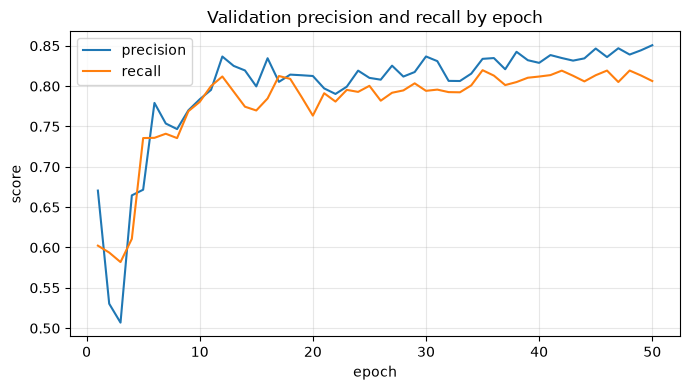

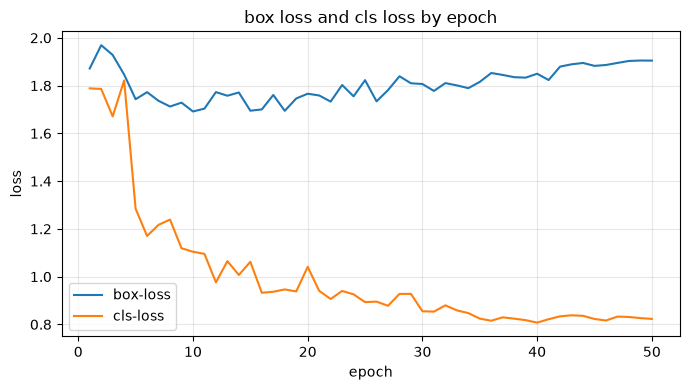

In [ ]:
# code for producing graphics tied to the training data

bestTrainFolder = 'runs/detect/train-final'
df = pd.read_csv('runs/detect/train-final/results.csv')
df.columns = df.columns.str.strip()

# convergence graph
plt.figure(figsize=(7, 4))
plt.plot(df["epoch"], df["metrics/precision(B)"], label="precision")
plt.plot(df["epoch"], df["metrics/recall(B)"], label="recall")
plt.xlabel("epoch")
plt.ylabel("score")
plt.title("Validation precision and recall by epoch")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("precision_recall_by_epoch.png", dpi=200)
plt.show()

# box-loss and cls-loss
plt.figure(figsize=(7, 4))
plt.plot(df["epoch"], df["val/box_loss"], label="box-loss")
plt.plot(df["epoch"], df["val/cls_loss"], label="cls-loss")
plt.xlabel("epoch")
plt.ylabel("loss")
plt.title("box loss and classification loss by epoch")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("loss_by_epoch.png", dpi=200)
plt.show()